# Air Quality Explorer — North Carolina, 2025
### Deliverable 2 · Python Data Analysis Notebook

**Source:** U.S. Environmental Protection Agency (EPA), [AirData — Daily AQI by County](https://aqs.epa.gov/aqsweb/airdata/download_files.html)  
**Raw file:** `daily_aqi_by_county_2025.csv` · **Output:** `nc_aqi_dashboard_2025.csv`  
**Audience:** North Carolina residents, environmental organizations, students, and local decision-makers.

**Research questions:**
1. **Geography:** Which reporting North Carolina counties have higher typical AQI, and do their high-AQI days tell a different story?
2. **Seasonality:** How do monthly AQI patterns differ across counties during 2025?
3. **AQI categories:** How frequently do daily county observations fall into Good, Moderate, and higher AQI categories, and how does this change by month?

This notebook follows the structure: inspect → diagnose → clean → explore → visualize and interpret → export → validate → dashboard handoff. **An AQI record represents a reported county-day, not an individual person's exposure.** Counties without reporting records are not represented. No conclusions about causes or health outcomes can be inferred from this dataset alone.

---
## 1. Load and understand the data
### 1.1 Import libraries and load CSV


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
RAW_FILE = "daily_aqi_by_county_2025.csv"
DASHBOARD_FILE = "nc_aqi_dashboard_2025.csv"

# Works in Colab after uploading the CSV, or locally beside the notebook.
if not Path(RAW_FILE).exists() and Path("/mnt/data", RAW_FILE).exists():
    RAW_FILE = str(Path("/mnt/data", RAW_FILE))

df_raw = pd.read_csv(RAW_FILE)
print("Loaded successfully! Rows and columns:", df_raw.shape)
display(df_raw.head())

Loaded successfully! Rows and columns: (323653, 10)


,State Name,county Name,State Code,County Code,Date,AQI,Category,Defining Parameter,Defining Site,Number of Sites Reporting
0,Alabama,Baldwin,1,3,2025-01-01,20,Good,PM2.5,01-003-0010,1
1,Alabama,Baldwin,1,3,2025-01-02,37,Good,PM2.5,01-003-0010,1
2,Alabama,Baldwin,1,3,2025-01-03,52,Moderate,PM2.5,01-003-0010,1
3,Alabama,Baldwin,1,3,2025-01-04,31,Good,PM2.5,01-003-0010,1
4,Alabama,Baldwin,1,3,2025-01-05,31,Good,PM2.5,01-003-0010,1


### 1.2 Structure, data types, and source metadata
EPA's downloadable daily county AQI report includes geographic identifiers, dates, reported AQI, AQI category, defining parameter/site, and number of reporting sites. Documentation: [EPA AirData reports](https://www.epa.gov/outdoor-air-quality-data/about-airdata-reports). The data dictionary below describes the **actual CSV headers**, including the lowercase `county Name` spelling.

In [2]:
print("Columns:", df_raw.columns.tolist())
print("\nShape:", df_raw.shape)
df_raw.info()
display(df_raw.describe(include="all").T)

Columns: ['State Name', 'county Name', 'State Code', 'County Code', 'Date', 'AQI', 'Category', 'Defining Parameter', 'Defining Site', 'Number of Sites Reporting']

Shape: (323653, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 323653 entries, 0 to 323652
Data columns (total 10 columns):
 #   Column                     Non-Null Count   Dtype 
---  ------                     --------------   ----- 
 0   State Name                 323653 non-null  object
 1   county Name                323653 non-null  object
 2   State Code                 323653 non-null  int64 
 3   County Code                323653 non-null  int64 
 4   Date                       323653 non-null  object
 5   AQI                        323653 non-null  int64 
 6   Category                   323653 non-null  object
 7   Defining Parameter         323653 non-null  object
 8   Defining Site              323653 non-null  object
 9   Number of Sites Reporting  323653 non-null  int64 
dtypes: int64(4), object(6)
memor

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
State Name,323653,54,California,16763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
county Name,323653,767,Washington,4432,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State Code,"323,653.00",NaN,NaN,NaN,30.26,16.03,1.00,17.00,30.00,42.00,80.00
County Code,"323,653.00",NaN,NaN,NaN,80.50,91.84,1.00,23.00,59.00,107.00,810.00
Date,323653,365,2025-04-13,973,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AQI,"323,653.00",NaN,NaN,NaN,41.43,19.83,0.00,31.00,40.00,51.00,"2,122.00"
Category,323653,6,Good,242305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Defining Parameter,323653,5,Ozone,160445,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Defining Site,323653,1962,12-097-2002,365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Number of Sites Reporting,"323,653.00",NaN,NaN,NaN,2.00,2.49,1.00,1.00,1.00,2.00,33.00


| Original column | Meaning | Expected type |
|---|---|---|
| `State Name`, `county Name` | Geographic labels | text |
| `State Code`, `County Code` | Geographic identifiers (codes, not measurements) | integer / ID |
| `Date` | Calendar date of county AQI report | date (initially text) |
| `AQI` | Reported daily Air Quality Index | numeric |
| `Category` | EPA AQI classification | category/text |
| `Defining Parameter` | Pollutant driving the reported AQI | category/text |
| `Defining Site` | Monitoring site identifier associated with the defining AQI | text/ID |
| `Number of Sites Reporting` | Reporting monitor count | integer |

**Metadata caution:** A county AQI summary is not a complete measurement of all places within a county. A daily category is based on the reported AQI; we do not treat the number of sites as a population or exposure weight.

### 1.3 Diagnose data quality before changing anything
We check missing cells, duplicate rows and geographic/date keys, date parsing, plausible AQI values, and category consistency. A national file with no missing cells may still have uneven monitoring coverage.

In [3]:
missing = pd.DataFrame({
    "Missing": df_raw.isna().sum(),
    "Missing_%": (100 * df_raw.isna().mean()).round(2)
})
display(missing)
print("Exact duplicates:", df_raw.duplicated().sum())
print("Duplicate state/county/date keys:", df_raw.duplicated(["State Code", "County Code", "Date"]).sum())
parsed_dates = pd.to_datetime(df_raw["Date"], errors="coerce")
print("Invalid dates:", parsed_dates.isna().sum())
print("Date range:", parsed_dates.min().date(), "through", parsed_dates.max().date())
print("AQI min/max:", df_raw["AQI"].min(), df_raw["AQI"].max())
print("Nonpositive reporting-site counts:", (df_raw["Number of Sites Reporting"] <= 0).sum())
print("National AQI categories:")
display(df_raw["Category"].value_counts().to_frame("Records"))

,Missing,Missing_%
State Name,0,0.00
county Name,0,0.00
State Code,0,0.00
County Code,0,0.00
Date,0,0.00
AQI,0,0.00
Category,0,0.00
Defining Parameter,0,0.00
Defining Site,0,0.00
Number of Sites Reporting,0,0.00


Exact duplicates: 0
Duplicate state/county/date keys: 0
Invalid dates: 0
Date range: 2025-01-01 through 2025-12-31
AQI min/max: 0 2122
Nonpositive reporting-site counts: 0
National AQI categories:


,Records
Category,
Good,242305
Moderate,78193
Unhealthy for Sensitive Groups,2471
Unhealthy,582
Hazardous,53
Very Unhealthy,49


### 1.4 Data-quality findings and planned fixes

| Observation | Evidence / test | Action |
|---|---|---|
| Date stored as text | `Date` is initially `object` | Convert to datetime; reject unparseable dates |
| No missing fields in source | Missing-value count check | Do not invent or impute values |
| No duplicate full rows or county-date keys | Duplicate checks | Retain one county-day per geographic key; log any removals |
| National scope is broader than our question | State names | Filter to North Carolina |
| Different numbers of reported days per county | Coverage analysis below | Display counts; use ≥300 reported days for ranked county comparison |
| Some counties have no records | Only counties present can be analyzed | Explicitly limit findings to reporting counties |
| Potential invalid AQI/site counts | Range checks | Exclude only genuinely invalid rows, if any; log removals |

**Interpretation principle:** Fewer than 365 county-days is not the same as a missing value inside an existing row. We will not fill unreported dates with zero AQI.

---
## 2. Clean and prepare North Carolina data
We work on a copy, log changes, preserve original source fields until export, and create useful date and AQI indicators.

In [4]:
df = df_raw.copy()
cleaning_log = []

def log_change(step, before, after):
    cleaning_log.append({"Step": step, "Before": before, "After": after, "Removed": before - after})

before = len(df)
df = df.drop_duplicates()
log_change("Remove exact duplicates", before, len(df))

for col in ["State Name", "county Name", "Category", "Defining Parameter"]:
    df[col] = df[col].astype("string").str.strip()

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
before = len(df)
df = df.dropna(subset=["Date", "AQI", "State Name", "county Name"])
log_change("Remove missing essential values / invalid dates", before, len(df))

before = len(df)
df = df[(df["AQI"] >= 0) & (df["AQI"] <= 500) & (df["Number of Sites Reporting"] > 0)]
log_change("Remove implausible AQI or site counts", before, len(df))

before = len(df)
df = df[df["State Name"] == "North Carolina"].copy()
log_change("Keep North Carolina records", before, len(df))

before = len(df)
df = df.drop_duplicates(subset=["State Code", "County Code", "Date"])
log_change("Ensure unique county-date keys", before, len(df))

df["County"] = df["county Name"].astype(str)
df["AQI_Category"] = df["Category"].astype(str)
df["Defining_Pollutant"] = df["Defining Parameter"].astype(str)
df["Month"] = df["Date"].dt.month
df["Month_Label"] = df["Date"].dt.strftime("%b")
df["Year"] = df["Date"].dt.year
df["High_AQI"] = df["AQI"] > 100

display(pd.DataFrame(cleaning_log))
print("Clean North Carolina shape:", df.shape)
display(df.head())

,Step,Before,After,Removed
0,Remove exact duplicates,323653,323653,0
1,Remove missing essential values / invalid dates,323653,323653,0
2,Remove implausible AQI or site counts,323653,323633,20
3,Keep North Carolina records,323633,10536,313097
4,Ensure unique county-date keys,10536,10536,0


Clean North Carolina shape: (10536, 17)


,State Name,county Name,State Code,County Code,Date,AQI,Category,Defining Parameter,Defining Site,Number of Sites Reporting,County,AQI_Category,Defining_Pollutant,Month,Month_Label,Year,High_AQI
192556,North Carolina,Alexander,37,3,2025-03-01,47,Good,Ozone,37-003-0005,1,Alexander,Good,Ozone,3,Mar,2025,False
192557,North Carolina,Alexander,37,3,2025-03-02,41,Good,Ozone,37-003-0005,1,Alexander,Good,Ozone,3,Mar,2025,False
192558,North Carolina,Alexander,37,3,2025-03-03,43,Good,Ozone,37-003-0005,1,Alexander,Good,Ozone,3,Mar,2025,False
192559,North Carolina,Alexander,37,3,2025-03-04,42,Good,Ozone,37-003-0005,1,Alexander,Good,Ozone,3,Mar,2025,False
192560,North Carolina,Alexander,37,3,2025-03-05,44,Good,Ozone,37-003-0005,1,Alexander,Good,Ozone,3,Mar,2025,False


### 2.1 Verify cleaning and reporting coverage
A county with 100 reported days should not be compared uncritically with one that has 365. The full dataset is retained for exploratory work; **ranked comparisons use counties with at least 300 reported days**. This is a transparent analysis choice, not an EPA standard.

In [5]:
print("Duplicates by county/date:", df.duplicated(["County", "Date"]).sum())
print("Missing values after cleaning:", df.isna().sum().sum())
print("Unique counties:", df["County"].nunique())
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())

county_coverage = df.groupby("County").agg(
    Reported_Days=("Date", "nunique"),
    Average_AQI=("AQI", "mean"),
    P90_AQI=("AQI", lambda x: x.quantile(0.90)),
    Maximum_AQI=("AQI", "max")
).sort_values("Reported_Days")
county_coverage["Coverage_%"] = 100 * county_coverage["Reported_Days"] / 365
print("Full 365-day counties:", (county_coverage["Reported_Days"] == 365).sum())
print("Counties with at least 300 days:", (county_coverage["Reported_Days"] >= 300).sum())
display(county_coverage.round(1))

Duplicates by county/date: 0
Missing values after cleaning: 0
Unique counties: 34
Date range: 2025-01-01 to 2025-12-31
Full 365-day counties: 13
Counties with at least 300 days: 20


,Reported_Days,Average_AQI,P90_AQI,Maximum_AQI,Coverage_%
County,,,,,
Hyde,97,26.00,43.40,59,26.60
Person,237,37.10,47.00,74,64.90
Granville,238,39.20,49.00,87,65.20
Lincoln,242,41.30,50.90,87,66.30
Rockingham,243,38.70,47.00,74,66.60
Alexander,245,38.80,48.60,80,67.10
Caswell,245,37.90,47.00,77,67.10
Caldwell,245,36.70,46.00,77,67.10
Graham,245,41.60,50.60,97,67.10


---
## 3. Descriptive exploration
We summarize AQI distribution, categories, pollutants, and monthly trends before selecting the dashboard charts.

In [6]:
print("AQI descriptive statistics:")
display(df["AQI"].describe(percentiles=[0.1, 0.5, 0.9, 0.95]).to_frame("AQI"))
print("AQI categories:")
display(df["AQI_Category"].value_counts().to_frame("County-days"))
print("Defining pollutants:")
display(df["Defining_Pollutant"].value_counts().to_frame("County-days"))
print("Reported county-days with AQI > 100:", int(df["High_AQI"].sum()))

AQI descriptive statistics:


,AQI
count,"10,536.00"
mean,39.54
std,12.67
min,0.00
10%,24.00
50%,39.00
90%,55.00
95%,60.00
max,121.00


AQI categories:


,County-days
AQI_Category,
Good,8531
Moderate,2002
Unhealthy for Sensitive Groups,3


Defining pollutants:


,County-days
Defining_Pollutant,
Ozone,5809
PM2.5,4666
PM10,54
NO2,7


Reported county-days with AQI > 100: 3


### 3.1 Extra exploratory chart — AQI distribution
This histogram helps determine whether the average alone describes the data adequately. It is useful for analysis, but the three research-question charts below will be prioritized for the dashboard.

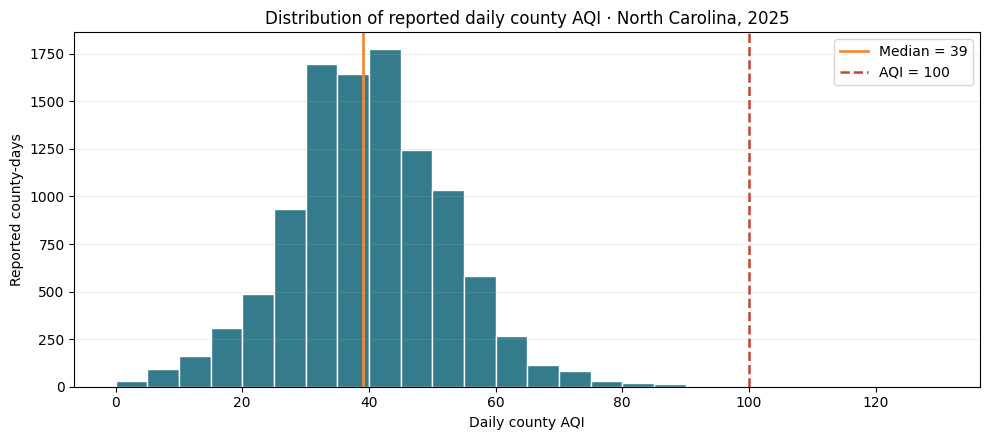

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(df["AQI"], bins=np.arange(0, max(130, df["AQI"].max()+10), 5), color="#347b8c", edgecolor="white")
ax.axvline(df["AQI"].median(), color="#ed8c40", lw=2, label=f"Median = {df['AQI'].median():.0f}")
ax.axvline(100, color="#c44536", lw=1.8, ls="--", label="AQI = 100")
ax.set(title="Distribution of reported daily county AQI · North Carolina, 2025", xlabel="Daily county AQI", ylabel="Reported county-days")
ax.legend(); ax.grid(axis="y", alpha=.2); plt.tight_layout(); plt.show()

---
## 4. Research question 1 — Which counties have higher typical and high-end AQI?
### Chart 1: Ranked dumbbell comparison — average versus 90th-percentile AQI
A plain average-only bar chart can conceal occasional higher-AQI days. A **dumbbell chart** shows both each county's mean and its 90th percentile, with the reporting-day count beside the county. We limit the ranking to counties with **at least 300 reported days**, then show the 12 highest mean AQIs in that group. The percentile describes the distribution of reported days, **not** an EPA regulatory threshold.

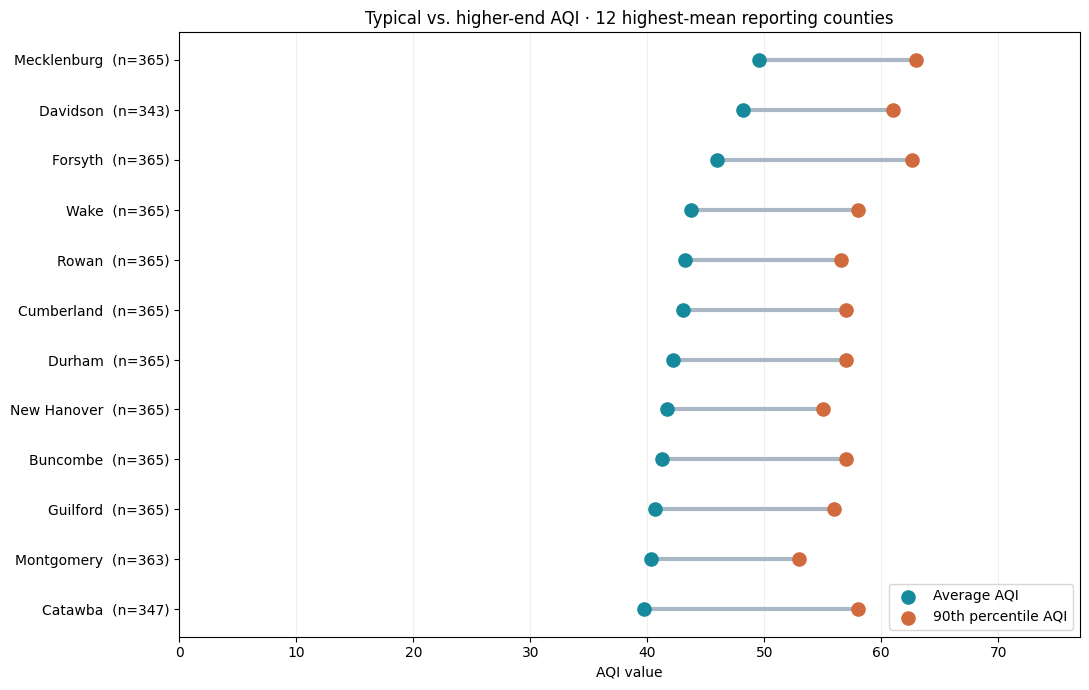

,Mean,P90,Days
County,,,
Mecklenburg,49.60,63.00,365
Davidson,48.20,61.00,343
Forsyth,46.00,62.60,365
Wake,43.70,58.00,365
Rowan,43.20,56.60,365
Cumberland,43.10,57.00,365
Durham,42.20,57.00,365
New Hanover,41.70,55.00,365
Buncombe,41.30,57.00,365


In [8]:
eligible = county_coverage.query("Reported_Days >= 300").index
q1 = (df[df["County"].isin(eligible)]
      .groupby("County")["AQI"]
      .agg(Mean="mean", P90=lambda x: x.quantile(.90), Days="count")
      .sort_values("Mean", ascending=False))
q1_top = q1.head(12).sort_values("Mean")
fig, ax = plt.subplots(figsize=(11, 7))
y = np.arange(len(q1_top))
ax.hlines(y, q1_top["Mean"], q1_top["P90"], color="#a9b8c4", lw=3)
ax.scatter(q1_top["Mean"], y, s=90, color="#168a9c", label="Average AQI", zorder=3)
ax.scatter(q1_top["P90"], y, s=90, color="#d16a3d", label="90th percentile AQI", zorder=3)
ax.set_yticks(y, [f"{name}  (n={int(row.Days)})" for name, row in q1_top.iterrows()])
ax.set(xlabel="AQI value", title="Typical vs. higher-end AQI · 12 highest-mean reporting counties")
ax.grid(axis="x", alpha=.2); ax.legend(loc="lower right")
ax.set_xlim(0, max(q1_top["P90"]) + 14)
plt.tight_layout(); plt.show()
display(q1.head(12).round(1))

**What this shows.** The teal marker represents a county's average AQI; the orange marker shows a value at or above which roughly 10% of its reported daily AQIs fall. The distance between them reveals how much higher-end days differ from typical conditions. County labels show sample sizes.

**Why it matters.** Residents and community organizations can compare *both* everyday reported conditions and occasional higher readings rather than relying on one ranking. **Important limitation:** these are selected reporting counties, not a complete ranking of all 100 North Carolina counties. Monitoring coverage and pollutant mix differ by location.

---
## 5. Research question 2 — How does air quality change across months and counties?
### Chart 2: County-by-month AQI heatmap
This heatmap is more informative than a single statewide line because it reveals **whether different counties experience similar or different monthly patterns**. We use the same 12 counties as Chart 1, with monthly mean AQI calculated from reported days only.

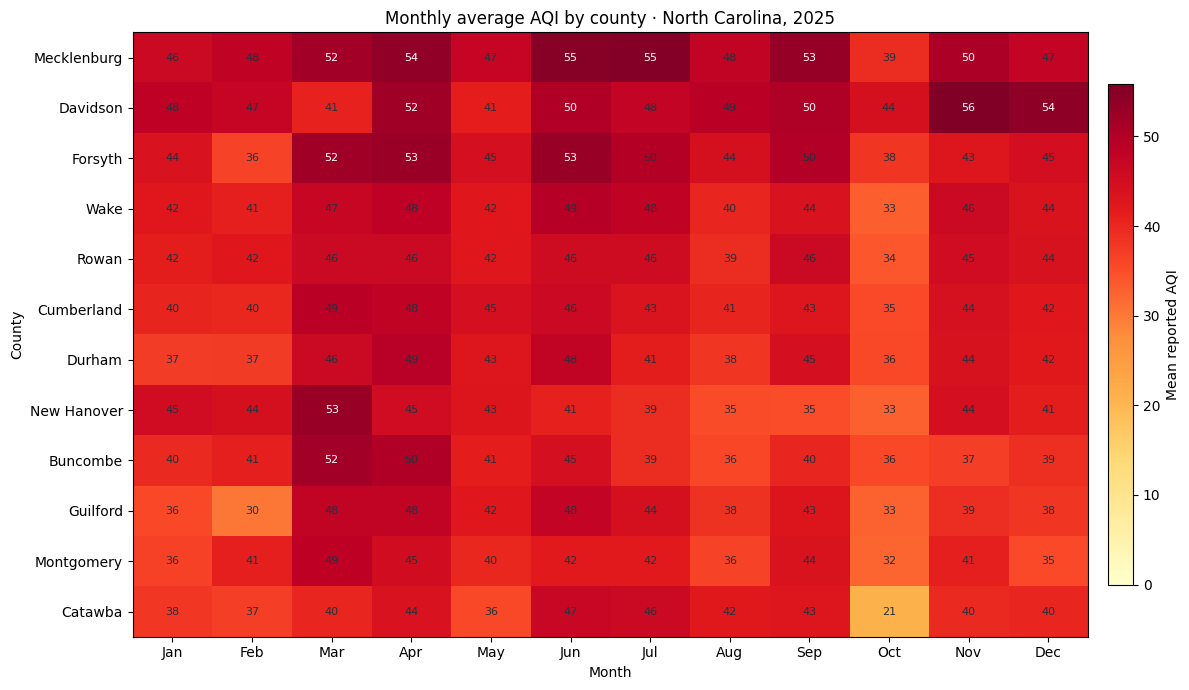

,Mean_AQI,County_Days
Month,,
1,34.50,674
2,35.90,595
3,45.50,1009
4,45.30,978
5,39.90,1026
6,43.00,985
7,40.40,1015
8,35.60,1030
9,39.60,998


In [9]:
selected_counties = q1.head(12).index.tolist()
q2 = (df[df["County"].isin(selected_counties)]
      .groupby(["County", "Month"])["AQI"].agg(Mean_AQI="mean", Days="count").reset_index())
heat = q2.pivot(index="County", columns="Month", values="Mean_AQI").reindex(selected_counties)
fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(heat.to_numpy(), aspect="auto", cmap="YlOrRd", vmin=0)
ax.set_xticks(np.arange(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(np.arange(len(heat)), heat.index)
for i in range(len(heat)):
    for j in range(12):
        value = heat.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if value > 50 else "#25313d")
ax.set(title="Monthly average AQI by county · North Carolina, 2025", xlabel="Month", ylabel="County")
cbar = fig.colorbar(im, ax=ax, fraction=.025, pad=.02); cbar.set_label("Mean reported AQI")
plt.tight_layout(); plt.show()
monthly = df.groupby("Month")["AQI"].agg(Mean_AQI="mean", County_Days="count")
display(monthly.round(1))

**What this shows.** Each cell is the average of the reported AQI values for one county during one month; deeper shades indicate higher monthly averages. It is not a daily forecast or a claim about the cause of pollution.

**Why it matters.** A resident can see whether a county's elevated months coincide with those of other counties. Local groups can use this as a starting point for questions about seasonal patterns, while remembering that some counties/months have fewer reporting days. The dashboard will allow county and date selection rather than fixing the view to these 12.

---
## 6. Research question 3 — How often does AQI fall into each category?
### Chart 3: 100% stacked monthly AQI-category composition
A standard count bar would be dominated by the large number of Good days. A **100% stacked bar chart** makes the category mix visible across months; a separate annotation gives the exact number of rare observations above AQI 100. The unit is **reported county-days**, not unique calendar days statewide.

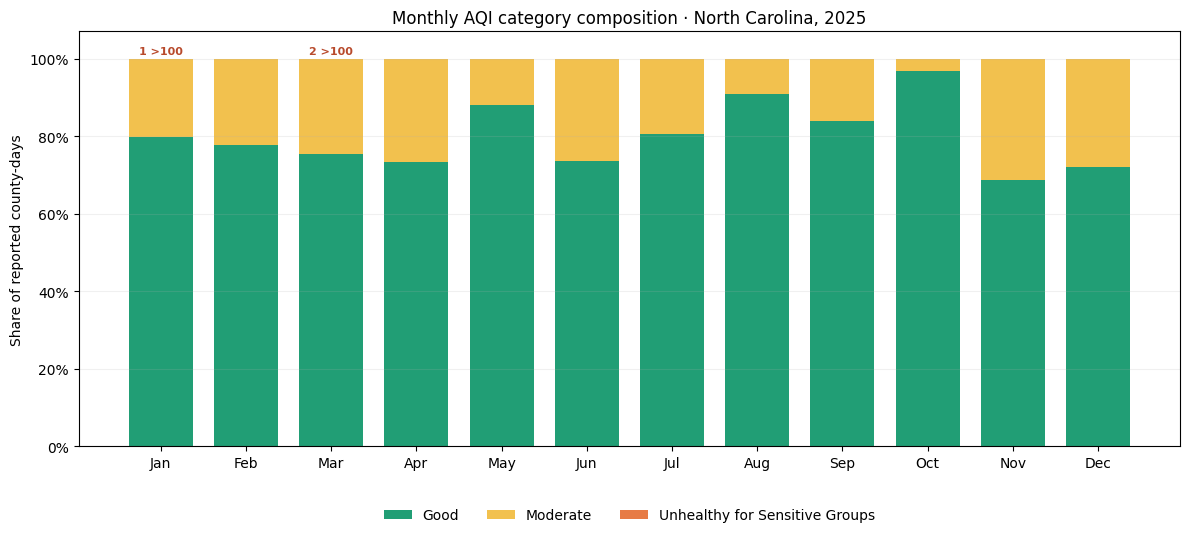

Category counts for the year:


,County-days
AQI_Category,
Good,8531
Moderate,2002
Unhealthy for Sensitive Groups,3
Unhealthy,0
Very Unhealthy,0
Hazardous,0


Monthly category shares (%):


AQI_Category,Good,Moderate,Unhealthy for Sensitive Groups,Unhealthy,Very Unhealthy,Hazardous
Month,,,,,,
1,79.82,20.03,0.15,0.00,0.00,0.00
2,77.82,22.18,0.00,0.00,0.00,0.00
3,75.32,24.48,0.20,0.00,0.00,0.00
4,73.31,26.69,0.00,0.00,0.00,0.00
5,88.01,11.99,0.00,0.00,0.00,0.00
6,73.60,26.40,0.00,0.00,0.00,0.00
7,80.49,19.51,0.00,0.00,0.00,0.00
8,90.97,9.03,0.00,0.00,0.00,0.00
9,83.97,16.03,0.00,0.00,0.00,0.00


In [10]:
category_order = ["Good", "Moderate", "Unhealthy for Sensitive Groups", "Unhealthy", "Very Unhealthy", "Hazardous"]
q3_counts = (df.groupby(["Month", "AQI_Category"]).size()
             .unstack(fill_value=0).reindex(index=range(1,13), fill_value=0))
q3_counts = q3_counts.reindex(columns=category_order, fill_value=0)
q3_pct = q3_counts.div(q3_counts.sum(axis=1), axis=0).mul(100)
colors = {"Good":"#219e75", "Moderate":"#f2c14e", "Unhealthy for Sensitive Groups":"#e77b45",
          "Unhealthy":"#d64545", "Very Unhealthy":"#8f4b8f", "Hazardous":"#6c3a48"}
fig, ax = plt.subplots(figsize=(12, 5.5))
bottom = np.zeros(12)
for cat in category_order:
    vals = q3_pct[cat].to_numpy()
    if q3_counts[cat].sum() > 0:
        ax.bar(np.arange(12), vals, bottom=bottom, color=colors[cat], label=cat, width=.75)
    bottom += vals
ax.set_xticks(np.arange(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylim(0, 107); ax.yaxis.set_major_formatter(PercentFormatter())
ax.set(ylabel="Share of reported county-days", title="Monthly AQI category composition · North Carolina, 2025")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.12), ncol=3, frameon=False)
for i in range(12):
    high = int(q3_counts.loc[i+1, ["Unhealthy for Sensitive Groups", "Unhealthy", "Very Unhealthy", "Hazardous"]].sum())
    if high:
        ax.text(i, 101.2, f"{high} >100", ha="center", fontsize=8, color="#b84a2c", weight="bold")
ax.grid(axis="y", alpha=.18); plt.tight_layout(); plt.show()
print("Category counts for the year:")
display(q3_counts.sum().to_frame("County-days"))
print("Monthly category shares (%):")
display(q3_pct.round(2))

**What this shows.** Each month totals 100% of the county-day reports available for that month. Green is Good, yellow is Moderate, and orange/red represent higher AQI categories. The labels above bars flag months with rare reported county-days above AQI 100; tiny segments may be visually difficult to see.

**Why it matters.** The chart distinguishes a month with mostly Good observations from one with a larger Moderate share. Residents can understand the frequency of different reported AQI categories without interpreting raw AQI scores. **Caution:** proportions depend on which counties reported each month, so changing geographic coverage may affect comparisons.

### 6.1 Bonus exploratory chart — which pollutant most often defines the AQI?
This adds a different perspective, but it does **not** measure pollutant concentrations or source contributions. It counts how often each pollutant was the *defining parameter* for the reported county AQI.

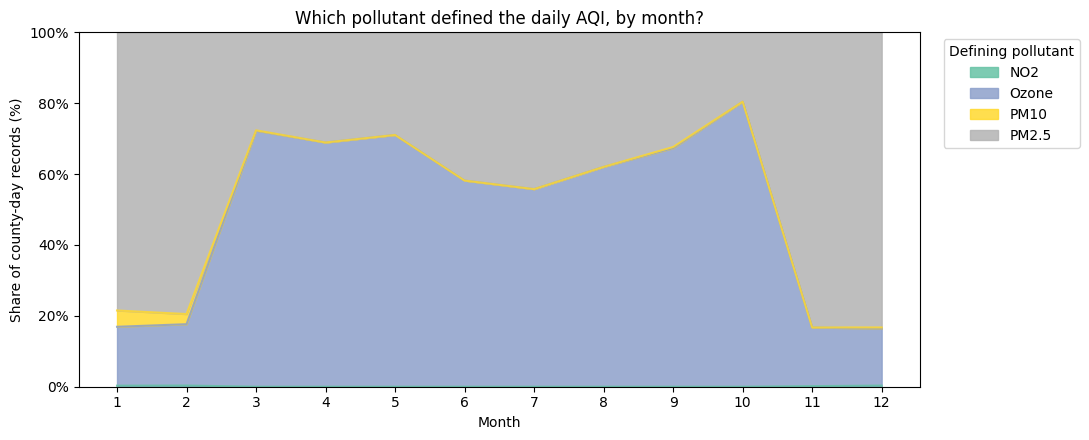

In [11]:
pollutant = pd.crosstab(df["Month"], df["Defining_Pollutant"], normalize="index").mul(100)
fig, ax = plt.subplots(figsize=(11, 4.5))
pollutant.plot(kind="area", stacked=True, ax=ax, alpha=.85, colormap="Set2")
ax.set(xlabel="Month", ylabel="Share of county-day records (%)", title="Which pollutant defined the daily AQI, by month?")
ax.set_xticks(range(1, 13)); ax.set_ylim(0,100)
ax.yaxis.set_major_formatter(PercentFormatter())
ax.legend(title="Defining pollutant", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

**Interpretation.** This chart shows the changing composition of defining pollutants across months, not their measured concentrations. It could become an optional fourth chart or an additional pollutant filter in the dashboard, but it is not one of the three primary research-question charts.

---
## 7. Which three charts belong in the dashboard?

| Priority | Visualization | Research question | Useful dashboard filters | Why it earns a place |
|---|---|---|---|---|
| 1 | **Mean vs. 90th-percentile dumbbell** | Q1: county differences | County selector; date range; minimum reporting-days threshold | Shows typical and higher-end AQI with sample sizes |
| 2 | **County × month heatmap** | Q2: seasonal patterns | County multiselect; date range | Reveals county-specific seasonal variation |
| 3 | **100% stacked AQI-category chart** | Q3: frequency of AQI categories | County multiselect; date range | Makes proportions comparable across months and highlights rare high-AQI reports |

**Why not choose the histogram or defining-pollutant area chart as primary?** They help interpret the data, but the three selected charts answer the three proposal questions more directly and offer complementary geographic, temporal, and category views.

**Dashboard metrics:** average AQI; number of reported county-days; percentage of reported county-days with AQI > 100; optionally number of reporting counties. The dashboard should state the selected filters and sample size alongside the metrics.

---
## 8. Export a small dashboard-ready CSV
We retain **all valid North Carolina county-days** (not just the 12 counties shown in charts) so users can explore any reporting county. We remove redundant national/source fields and keep only the attributes needed for filters, metrics, and charts. No unreported county-days are fabricated.

In [12]:
dashboard_cols = ["Date", "County", "AQI", "AQI_Category", "Defining_Pollutant", "Number of Sites Reporting", "Month", "Month_Label", "Year", "High_AQI"]
dash = df[dashboard_cols].copy().rename(columns={"Number of Sites Reporting":"Sites_Reporting"})
dash = dash.sort_values(["Date", "County"]).reset_index(drop=True)
dash.to_csv(DASHBOARD_FILE, index=False)
size_mb = Path(DASHBOARD_FILE).stat().st_size / (1024 ** 2)
print(f"Saved {DASHBOARD_FILE}: {len(dash):,} rows x {dash.shape[1]} columns; {size_mb:.3f} MiB")
assert size_mb < 25, "Dashboard CSV exceeds 25 MiB; reduce columns or consult instructor"
display(dash.head())

Saved nc_aqi_dashboard_2025.csv: 10,536 rows x 10 columns; 0.536 MiB


,Date,County,AQI,AQI_Category,Defining_Pollutant,Sites_Reporting,Month,Month_Label,Year,High_AQI
0,2025-01-01,Avery,4,Good,PM2.5,1,1,Jan,2025,False
1,2025-01-01,Buncombe,14,Good,PM2.5,1,1,Jan,2025,False
2,2025-01-01,Carteret,32,Good,Ozone,1,1,Jan,2025,False
3,2025-01-01,Catawba,3,Good,PM2.5,1,1,Jan,2025,False
4,2025-01-01,Cumberland,7,Good,PM2.5,1,1,Jan,2025,False


### 8.1 Validate the exported file
Reload the CSV as the future Streamlit app will. Confirm row count, dates, unique county-days, and categories. The raw CSV may be larger than 25 MB; **the assignment's size target applies to the prepared dashboard CSV**.

In [13]:
check = pd.read_csv(DASHBOARD_FILE, parse_dates=["Date"])
print("Reloaded shape:", check.shape)
print("Date range:", check["Date"].min().date(), "to", check["Date"].max().date())
print("Reporting counties:", check["County"].nunique())
print("Missing values:", check.isna().sum().sum())
print("Duplicate county-date keys:", check.duplicated(["County", "Date"]).sum())
assert len(check) == len(df)
assert check.duplicated(["County", "Date"]).sum() == 0
assert check["County"].nunique() == df["County"].nunique()
assert set(check["AQI_Category"]) == set(df["AQI_Category"])
print("Dashboard export validated.")

Reloaded shape: (10536, 10)
Date range: 2025-01-01 to 2025-12-31
Reporting counties: 34
Missing values: 0
Duplicate county-date keys: 0
Dashboard export validated.


---
## 9. Dashboard handoff specification (Deliverable 3)

**CSV:** `nc_aqi_dashboard_2025.csv` (same directory as `app.py`).

**Dependencies:** `streamlit`, `pandas`, `numpy`, `matplotlib` (optional `seaborn` if desired).

**Read data:**
```python
@st.cache_data
def load_data():
    return pd.read_csv("nc_aqi_dashboard_2025.csv", parse_dates=["Date"])
```

**Columns:** `Date` (datetime), `County` (text), `AQI` (integer), `AQI_Category` (text), `Defining_Pollutant` (text), `Sites_Reporting` (integer), `Month` (1–12), `Month_Label` (text), `Year` (integer), `High_AQI` (boolean, may reload as bool).

**Filters:** county multiselect, date-range picker, optionally pollutant and minimum reported days. Apply filters **before** recalculating all metrics and plots. Use the actual selected-date length (not 365) if implementing coverage percentages for a date-filtered view.

**Charts:** (1) county dumbbell mean vs 90th percentile with reported-day counts, (2) county-by-month mean AQI heatmap, (3) monthly 100% stacked category shares with high-AQI count annotation.

**Critical safeguards:** distinguish county-days from unique statewide days; do not fill absent days with AQI=0; show reporting counts; do not claim the dashboard provides live AQI or complete coverage of all North Carolina counties.

**Source:** https://aqs.epa.gov/aqsweb/airdata/download_files.html